# 15 — Primeras predicciones: ocho modelos y tres experimentos

## La pregunta y por qué importa

El proyecto busca predecir **cuántas solicitudes de triage llegarán al SES Hospital Universitario de
Caldas** como una **distribución** (un valor central y un rango), y de ahí la **probabilidad de que el
triage suba** por encima de lo que anuncia el calendario. Cada predicción debe ir acompañada de sus
**razones**: qué parte del contexto interno y externo la mueve. Una proyección del tipo «los lunes hay más
gente» no cumple ese propósito, porque no contesta por qué unos lunes suben más que otros.

Los cuadernos 01-14 sirvieron para decidir **con qué entrenar** y **cómo comprobar la fiabilidad**. Este
cuaderno reúne las primeras predicciones reales de ocho modelos, hechas con origen rodante sobre 2026, un
año que ningún modelo vio al entrenarse. El objetivo es ver cómo se comporta cada uno, qué aportan más años
de historia y qué aporta el contexto externo. Una confiabilidad de 60-70 % en acertar si el día sube o
baja es la meta de trabajo; por encima de eso habría que revisar el sobreentrenamiento o una fuga de
información.

## Diseño

| | Decisión |
|---|---|
| **Qué se predice** | El conteo diario de triage a 1-7 días, el año completo y la hora de saturación |
| **Qué entrega** | Una **distribución** (9 cuantiles). La regresión es un complemento explicable, no el método principal |
| **Qué es «subir»** | Superar lo que anuncia el calendario. **Pico** = superarlo en más de una desviación (≈ +11 %) |
| **Con qué se entrena** | Los años con registro (2020-2026), con la COVID marcada, y el contexto: salud, clima, social, red de salud, catástrofes, eventos y ENSO. **Solo lo que se sabe el día de la predicción** |
| **Contra qué se prueba** | **2026**, reentrenando cada 7 días con todo lo anterior |
| **Qué modelos** | Ingenuo, control de calendario, regresión binomial negativa, LightGBM, SARIMAX, Prophet, Chronos-2 (solo y con calendario). MedGemma se evalúa aparte, porque no entrega una distribución |

## Tres pruebas

| Prueba | Pregunta | Cómo |
|---|---|---|
| **1. Corto plazo** | ¿Qué pasará en los próximos 7 días? | Cada día de 2026 el modelo predice los 7 siguientes con lo que sabía hasta el día anterior |
| **2. El año a ciegas** | ¿Cómo será cada mes de 2026? | Una sola predicción hecha el 31-12-2025 y mantenida hasta septiembre |
| **3. La hora** | ¿A qué hora se satura el día predicho? | La predicción del día, repartida con el perfil horario de 2025 |

## Tres experimentos

| | Años de entrenamiento | Contexto externo |
|---|---|---|
| **E0** | 2022-2024 | no |
| **E1** | 2020-2025, con la COVID marcada | no |
| **E2** | 2020-2025, con la COVID marcada | **49 variables externas, todas presentes cada día** |

E1 frente a E0 mide qué aportan **más años**. E2 frente a E1 mide qué aporta **el contexto** cuando entra
completo y sin filtro. En el análisis aparece también E3, una variante con solo 8 variables externas
elegidas con datos hasta 2025, que sirve para comprobar si el resultado de E2 se debe a la cantidad de
variables.

Los experimentos se leen de las predicciones guardadas en `salidas/pronostico/`; este cuaderno no
reentrena nada. Un límite del diseño: SARIMAX con contexto completo (E2) no se evaluó en la prueba de
corto plazo. Por eso la comparación entre E1 y E2 a 1-7 días se apoya en la regresión, los árboles y
Prophet, y, para Chronos-2, en una versión con un origen cada 7 días. En la prueba del año a ciegas sí
hay un SARIMAX con contexto.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt
import pronostico as pr

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
COLOR = {"ingenuo": MUDO, "control": TINTA2, "glm_binneg": AZUL, "lightgbm": VERDE, "sarimax": VIOLETA,
         "prophet": AMARILLO, "chronos2": MAGENTA, "chronos2_cal": ROJO, "llm": NARANJA,
         "anio_pasado": MUDO, "regresion_anual": AZUL}
NOMBRE = {"ingenuo": "Ingenuo (semana pasada)", "control": "Control (calendario + nivel)", "glm_binneg": "Regresión binomial negativa",
          "lightgbm": "LightGBM (árboles)", "sarimax": "SARIMAX (serie de tiempo)", "prophet": "Prophet (serie de tiempo)",
          "chronos2": "Chronos-2 solo", "chronos2_cal": "Chronos-2 (IA de series)", "anio_pasado": "Igual que el año pasado",
          "regresion_anual": "Regresión anual (calendario + nivel)", "lightgbm_afinado": "LightGBM afinado",
          "xgboost_afinado": "XGBoost afinado", "gbr_afinado": "GradientBoosting afinado",
          "comb_sarimax_lightgbm": "SARIMAX + LightGBM (combinación)", "comb_4_modelos": "Combinación de 4 modelos"}
CRIT = ["BSS sube %", "BSS pico %", "R2 desvio %", "acierta sube/baja %", "AUC pico", "cob80 %", "error <=10 %", "MAPE %", "n"]
SEM = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
color = lambda m: COLOR.get(m.split("_cada")[0], COLOR["llm"] if m.startswith("llm") else MUDO)

def leer(exp, desde="2025-12-31", modelos=None):
    P, U = pr.leer(modelos or (pr.FASE_A if exp == "e0" else None), exp=exp)
    P = P[(P.origen >= desde) & ~P.modelo.str.startswith("llm") & ~P.modelo.str.contains("_cada")]
    if not modelos: P = P[~P.modelo.str.startswith("comb_") & ~P.modelo.str.endswith("_afinado") & (P.modelo != "lightgbm_rel")]
    return P, U

pr.usar("e2"); y, cal = pr.cargar()
print(f"triage diario: {y.notna().sum()} días con dato, {y.index[0].date()} a {y.index[-1].date()}")

triage diario: 2452 días con dato, 2020-01-01 a 2026-09-20


---
# 1. Los datos: qué se sabe y cuándo

La regla que manda sobre todas: **una predicción hecha el día *o* solo puede usar lo que se sabía el
día *o***. Lo que se sabe por adelantado (calendario, eventos programados) entra con el día que se
predice. Lo demás, con su último valor conocido.

,dato,fuente,¿cuándo se sabe?,capa
0,Triage diario,salidas/triage_diario.parquet,hasta el día de la predicción,nivel y memoria
1,Calendario de Colombia,calendario_Colombia.csv,por adelantado,calendario
2,COVID (dos fases),fechas fijas,por adelantado,calendario
3,"Feria, eventos de Manizales, fiestas de Caldas...","eventos_*, fiestas_*, calendario",por adelantado (programados),eventos
4,"IRA de Manizales (total, 0-4, 60+), consultas ...",Power BI 995 + microdatos,semana epidemiológica anterior,salud
5,"Agresión animal, intento de suicidio, varicela...",Power BI + microdatos,semana anterior,salud
6,"Temperatura, humedad, lluvia, radiación, vient...",clima_unificado.csv.gz,hasta el día anterior,clima
7,"Lesiones de tránsito, lesiones personales, hom...",seguridad_mindefensa.csv.gz,hasta el día anterior,social
8,Nueva EPS: cambio de 28 días y peso en el triage,triage_entidad.parquet,hasta el día de la predicción,red
9,Desastre activo (incluye el terremoto del 10-0...,desastres_manizales_2020_2026.csv,cuando ya empezó,catástrofe


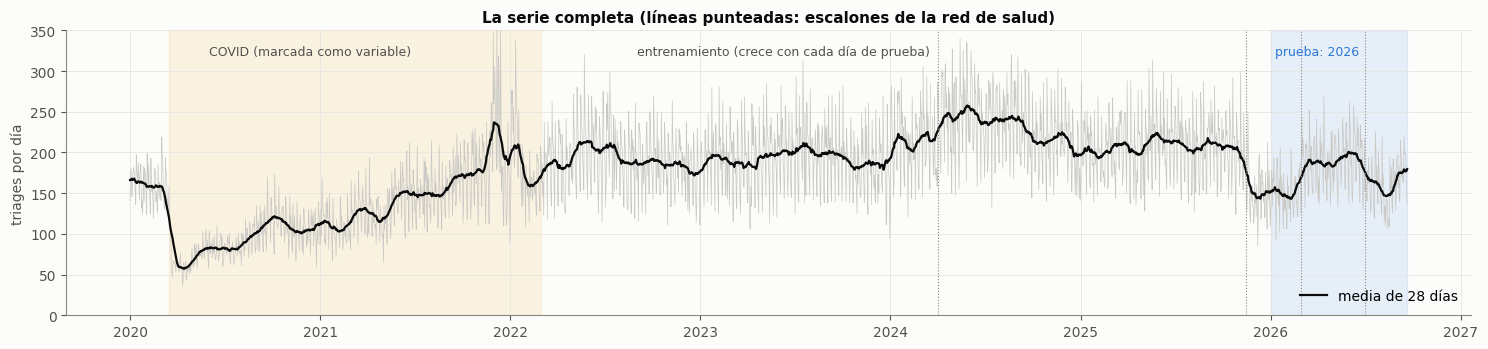

In [2]:
disp = pd.DataFrame([
    ["Triage diario", "salidas/triage_diario.parquet", "hasta el día de la predicción", "nivel y memoria"],
    ["Calendario de Colombia", "calendario_Colombia.csv", "por adelantado", "calendario"],
    ["COVID (dos fases)", "fechas fijas", "por adelantado", "calendario"],
    ["Feria, eventos de Manizales, fiestas de Caldas, días especiales", "eventos_*, fiestas_*, calendario", "por adelantado (programados)", "eventos"],
    ["IRA de Manizales (total, 0-4, 60+), consultas por toda causa", "Power BI 995 + microdatos", "semana epidemiológica anterior", "salud"],
    ["Agresión animal, intento de suicidio, varicela, violencia de género, intoxicaciones", "Power BI + microdatos", "semana anterior", "salud"],
    ["Temperatura, humedad, lluvia, radiación, viento (anomalías de 7 y 28 días)", "clima_unificado.csv.gz", "hasta el día anterior", "clima"],
    ["Lesiones de tránsito, lesiones personales, homicidio, violencia intrafamiliar", "seguridad_mindefensa.csv.gz", "hasta el día anterior", "social"],
    ["Nueva EPS: cambio de 28 días y peso en el triage", "triage_entidad.parquet", "hasta el día de la predicción", "red"],
    ["Desastre activo (incluye el terremoto del 10-08-2026)", "desastres_manizales_2020_2026.csv", "cuando ya empezó", "catástrofe"],
    ["ENSO (El Niño / La Niña)", "enso_oni.csv", "con dos meses de retraso", "ENSO"],
    ["Clima o IRA de los días que vienen", "—", "NO se sabe (no hay archivo histórico de pronósticos)", "no se usa"],
], columns=["dato", "fuente", "¿cuándo se sabe?", "capa"])
display(disp)

fig, ax = plt.subplots(figsize=(15, 3.6))
ax.plot(y.index, y.values, color="#c9c8c4", lw=.5)
ax.plot(y.index, y.rolling(28, center=True, min_periods=14).mean(), color=TINTA, lw=1.6, label="media de 28 días")
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2022-02-28"), color=AMARILLO, alpha=.10)
ax.axvspan(pd.Timestamp("2026-01-01"), y.index[-1], color=AZUL, alpha=.10)
ax.text(pd.Timestamp("2020-06-01"), 320, "COVID (marcada como variable)", color=TINTA2, fontsize=9)
ax.text(pd.Timestamp("2026-01-10"), 320, "prueba: 2026", color=AZUL, fontsize=9)
ax.text(pd.Timestamp("2022-09-01"), 320, "entrenamiento (crece con cada día de prueba)", color=TINTA2, fontsize=9)
for f in ["2024-04-01", "2025-11-15", "2026-03-01", "2026-07-01"]: ax.axvline(pd.Timestamp(f), color=MUDO, lw=.8, ls=":")
ax.set_ylim(0, 350); ax.set_ylabel("triages por día"); ax.legend(loc="lower right")
ax.set_title("La serie completa (líneas punteadas: escalones de la red de salud)"); plt.tight_layout(); plt.show()

**Lectura.** La serie tiene 2.452 días con dato entre el 1 de enero de 2020 y el 20 de septiembre de 2026. El modelo entrena con 2020-2025 y se prueba en 2026. La COVID va marcada como dos fases (el cráter de 2020 y la recuperación parcial hasta febrero de 2022), para que el modelo no confunda ese cráter con la forma normal del hospital. 2026 es una prueba exigente: trae escalones de Nueva EPS (marzo y julio) y un terremoto (10 de agosto) que el hospital no conoce con antelación, y la figura los marca con líneas punteadas junto con los cambios de 2024 y 2025.

Lo que no se sabe el día de la predicción no entra. El clima y la IRA de los días que vienen no se conocen y no existe un archivo histórico de pronósticos, así que el modelo trabaja con valores observados hasta el día anterior o hasta la semana epidemiológica previa. Esto equivale a lo que se tendría en operación, pero impide evaluar el efecto de un pronóstico del clima.

---
# 2. Las entradas, por capas

Cada capa es una razón posible de que un día tenga más o menos triage. Es lo que permite decir **por
qué** se mueve la predicción.

In [3]:
X2 = pr.rasgos(y, cal.reindex(y.index), 1, tuple(c.reindex(y.index) for c in pr.contexto(cal.index)))
capa = pd.Series(pr.capas(X2.columns))
resumen = capa.value_counts().rename("variables").to_frame()
resumen["ejemplos"] = [", ".join(capa[capa == k].index[:3]) for k in resumen.index]
print(f"{X2.shape[1]} entradas por día en E2")
resumen

77 entradas por día en E2


,variables,ejemplos
eventos,20,"fut_ev_feria, fut_ev_religioso, fut_ev_civico"
calendario,18,"dow_1, dow_2, dow_3"
clima,12,"ext_cli_temp_7d, ext_cli_temp_28d, ext_cli_tmi..."
salud,9,"ext_sal_ira_total, ext_sal_ira_0_4, ext_sal_ir..."
estacion,6,"four_s1, four_c1, four_s2"
social,4,"ext_soc_lesiones_transito, ext_soc_lesiones_pe..."
memoria,3,"mem_semana, mem_ultimo, mem_mismo_dia"
red,2,"ext_red_nueva_cambio, ext_red_nueva_peso"
nivel,1,nivel
catastrofe,1,ext_cat_desastre


**Lectura.** En E2 cada día llega con **77 entradas**: 28 internas (calendario 18, estación 6, memoria 3 y nivel 1) y 49 externas (eventos 20, clima 12, salud 9, social 4, red de salud 2, catástrofe 1 y ENSO 1). Las 20 de eventos son programadas (feria, fiestas, actos cívicos y religiosos) y valen cero casi todos los días.

E3 conserva solo 8 externas, las que un modelo entrenado con datos hasta 2025 encontró más útiles: IRA y consultas totales, cambio de la radiación, temperatura de 28 días, lesiones personales, violencia intrafamiliar, y peso y cambio de Nueva EPS.

---
# 3. Los modelos

| Modelo | Técnica | Cómo da la distribución | Ventaja | Riesgo |
|---|---|---|---|---|
| **Ingenuo** | base | lo de hace 7 días × su dispersión | nada que ajustar | no ve nada más |
| **Control** | base | calendario + nivel, en log | es la vara del proyecto | no ve estación ni contexto |
| **Regresión binomial negativa** | regresión de conteo | cada factor multiplica | **da las razones** directo | supone efectos que solo se suman en log |
| **LightGBM** | árboles con refuerzo | un modelo por cuantil | capta interacciones | se sobreajusta con pocos datos |
| **SARIMAX** | serie de tiempo clásica | error gaussiano del log, que crece con el horizonte | **se actualiza cada día** con lo que acaba de pasar | lineal |
| **Prophet** | serie de tiempo por componentes | simulación | buena para estaciones largas | no tiene memoria de corto plazo |
| **Chronos-2** | modelo fundacional de series (IA preentrenada) | cuantiles directos | **no se entrena con estos datos** | caja negra y lento con muchas covariables |
| **MedGemma** | modelo de lenguaje médico | un solo número (no da distribución) | — | no está hecho para series |

**Detalles que cuentan:**
- Todos se reentrenan cada 7 días con todo lo anterior.
- Ningún parámetro se eligió mirando 2026.

---
# 4. Cómo se mide

Casi todo el error de un modelo de triage es calendario: el control de calendario y nivel ya tiene un MAPE
de alrededor del 11 %, y el mejor modelo apenas lo baja a 9 %. Un criterio basado en el MAPE premia acertar
el lunes, que es proyección, y no distingue a un modelo que anticipa de uno que repite el calendario. Por
eso **el criterio para llamar «mejor» a un modelo** es el acierto en sube/baja frente al calendario, junto
con la mejora de la probabilidad (BSS) y la cobertura del rango del 80 %. El MAPE y el error de 10 % se
reportan solo para comunicar.

| Criterio | Qué mide | Cómo se lee |
|---|---|---|
| **Acierta si sube o baja** | Si el día quedó por encima o por debajo de lo que anunciaba el calendario, como dijo el modelo | 50 % es adivinar. La meta es 60-70 % |
| **Mejora de la probabilidad (BSS)** | Si su «60 % de que suba» vale más que decir siempre la tasa normal | Positivo, sirve; negativo, es peor que no tener modelo |
| **Cobertura del 80 %** | De cada 100 días, cuántos cayeron dentro del rango que el modelo prometió con 80 % | 75-85 % es honesto. Menos indica exceso de confianza, que suele venir de sobreajuste |
| Desvío anticipado (R²) | De lo que el calendario no explica, cuánto vio venir | 0 % es no saber más que el calendario |
| Error ≤ 10 % y MAPE | Cercanía del número | Solo para comunicar |

El «sube» se define contra lo que anuncia el control de calendario de E0, y es la misma vara para todos
los experimentos. Con esa vara, la tasa de días que suben en 2026 no es 50 %, porque el control sigue el
nivel de los últimos 28 días y la serie cayó a escalones.

---
# 5. Prueba 1: corto plazo, cada día de 2026

## 5.1 Los tres experimentos, modelo por modelo

La tabla ordena los modelos por la mejora de la probabilidad y reúne los criterios que deciden. Una celda
vacía indica que esa combinación de modelo y experimento no se evaluó.

acierta sube/baja %                   BSS sube %  \
exp                                           e0    e1    e2    e3         e0   
modelo_                                                                         
SARIMAX (serie de tiempo)                   65.7  66.8   NaN  65.0       17.2   
LightGBM (árboles)                          60.4  67.8  62.6  64.9        1.6   
Regresión binomial negativa                 64.3  65.0  59.9  62.5        9.1   
Chronos-2 (IA de series)                    62.6  65.6   NaN  65.4        9.6   
Chronos-2 solo                              64.2   NaN   NaN   NaN        5.4   
Control (calendario + nivel)                52.4   NaN   NaN   NaN       -0.2   
Ingenuo (semana pasada)                     56.8   NaN   NaN   NaN       -3.7   
Prophet (serie de tiempo)                   41.0  42.7  52.0   NaN      -38.7   

                                               BSS pico %                    \
exp                             e1    e2    e3         e0    e1    e2    e3   
modelo_                                                                       
SARIMAX (serie de tiempo)     18.8   NaN  16.3       14.2  13.3   NaN  12.2   
LightGBM (árboles)            15.9   6.4   8.5       -0.2  11.4   5.2   3.9   
Regresión binomial negativa   14.5   6.3  11.0        8.1  11.1   6.2   8.7   
Chronos-2 (IA de series)      12.1   NaN  13.3       11.9  13.1   NaN  12.9   
Chronos-2 solo                 NaN   NaN   NaN        4.6   NaN   NaN   NaN   
Control (calendario + nivel)   NaN   NaN   NaN       -0.7   NaN   NaN   NaN   
Ingenuo (semana pasada)        NaN   NaN   NaN      -14.6   NaN   NaN   NaN   
Prophet (serie de tiempo)    -35.1 -17.1   NaN      -30.6 -33.0 -12.4   NaN   

                             cob80 %                   MAPE %              \
exp                               e0    e1    e2    e3     e0    e1    e2   
modelo_                                                                     
SARIMAX (serie de tiempo)       80.4  85.4   NaN  84.5    9.2   9.0   NaN   
LightGBM (árboles)              70.7  71.2  73.0  74.0   11.1   9.8  10.7   
Regresión binomial negativa     79.0  84.0  78.4  82.7   10.0   9.5  10.2   
Chronos-2 (IA de series)        81.5  79.4   NaN  81.8    9.9   9.6   NaN   
Chronos-2 solo                  81.5   NaN   NaN   NaN   10.8   NaN   NaN   
Control (calendario + nivel)    69.3   NaN   NaN   NaN   10.9   NaN   NaN   
Ingenuo (semana pasada)         79.2   NaN   NaN   NaN   13.3   NaN   NaN   
Prophet (serie de tiempo)       55.9  61.3  69.4   NaN   12.8  13.9  11.7   

                                    
exp                             e3  
modelo_                             
SARIMAX (serie de tiempo)      9.1  
LightGBM (árboles)            10.4  
Regresión binomial negativa    9.9  
Chronos-2 (IA de series)       9.5  
Chronos-2 solo                 NaN  
Control (calendario + nivel)   NaN  
Ingenuo (semana pasada)        NaN  
Prophet (serie de tiempo)      NaN

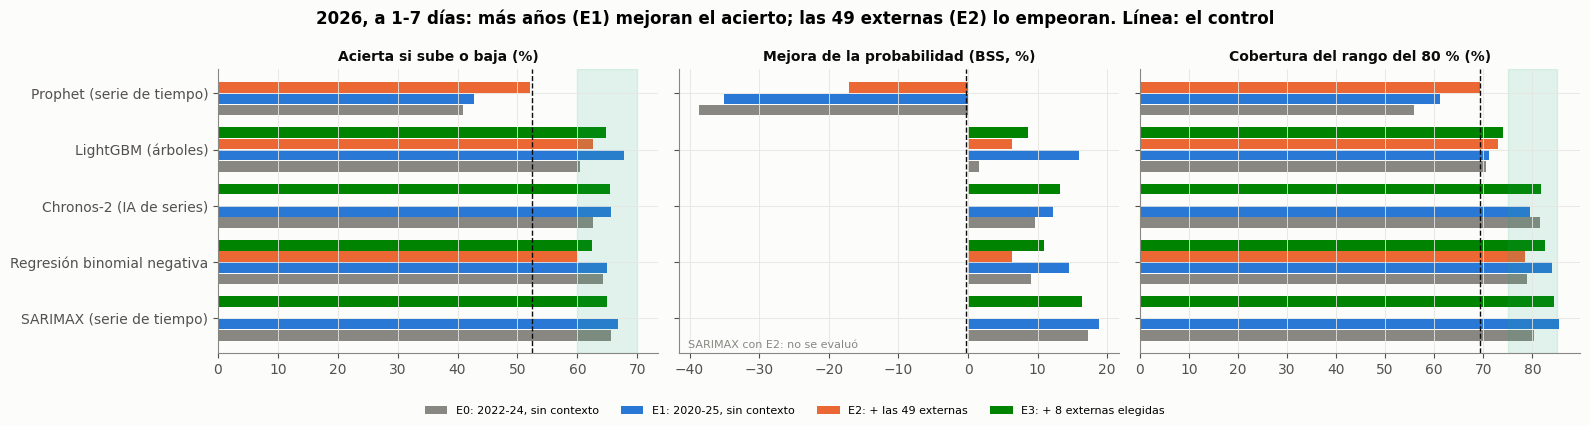

In [4]:
tablas = []
for e in ["e0", "e1", "e2", "e3"]:
    P, U = leer(e)
    P2, T = pr.metricas(P, U)
    tablas.append(T.assign(exp=e).reset_index())
R = pd.concat(tablas)
R["modelo_"] = R.modelo.map(NOMBRE)
ORD = ["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"]
tab = R.pivot_table(index="modelo_", columns="exp", values=ORD)[ORD]
tab = tab.reindex(tab[("BSS sube %", "e1")].fillna(tab[("BSS sube %", "e0")]).sort_values(ascending=False).index)
display(tab.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
mods = [m for m in ["sarimax", "glm_binneg", "chronos2_cal", "lightgbm", "prophet"] if m in set(R.modelo)]
for ax, (c, t) in zip(axes, [("acierta sube/baja %", "Acierta si sube o baja (%)"), ("BSS sube %", "Mejora de la probabilidad (BSS, %)"), ("cob80 %", "Cobertura del rango del 80 % (%)")]):
    for j, e in enumerate(["e0", "e1", "e2", "e3"]):
        v = R[R.exp == e].set_index("modelo").reindex(mods)[c]
        ax.barh(np.arange(len(mods)) + (j - 1.5) * .2, v.values, height=.19, color=[MUDO, AZUL, NARANJA, VERDE][j],
                label={"e0": "E0: 2022-24, sin contexto", "e1": "E1: 2020-25, sin contexto", "e2": "E2: + las 49 externas", "e3": "E3: + 8 externas elegidas"}[e])
    ax.set_title(t, fontsize=10)
    base = R[(R.exp == "e0") & (R.modelo == "control")][c].iloc[0]
    ax.axvline(base, color=TINTA, lw=1, ls="--")
axes[0].set_yticks(range(len(mods)), [NOMBRE[m] for m in mods]); axes[2].axvspan(75, 85, color=AQUA, alpha=.12)
axes[0].axvspan(60, 70, color=AQUA, alpha=.12)
h_, l_ = axes[2].get_legend_handles_labels(); fig.legend(h_, l_, fontsize=8, loc="lower center", ncol=4); axes[1].text(.02, .02, "SARIMAX con E2: no se evaluó", transform=axes[1].transAxes, fontsize=8, color=MUDO); fig.suptitle("2026, a 1-7 días: más años (E1) mejoran el acierto; las 49 externas (E2) lo empeoran. Línea: el control", fontweight="bold")
plt.tight_layout(rect=(0, .07, 1, 1)); plt.show()

**Lectura.** Con el criterio de la sección 4 (acierto en sube/baja, mejora de la probabilidad y cobertura del 80 %), la tabla y la figura muestran tres hechos.

**Más años de historia mejoran a los modelos con memoria.** De E0 a E1, LightGBM pasa de 60,4 % a 67,8 % de acierto y de +1,6 % a +15,9 % de mejora de la probabilidad. La regresión pasa de 64,3 % a 65,0 % y de +9,1 % a +14,5 %; SARIMAX, de 65,7 % a 66,8 % y de +17,2 % a +18,8 %; Chronos-2 con calendario, de 62,6 % a 65,6 % y de +9,6 % a +12,1 %. El control de calendario queda en 52,4 % y −0,2 %, lo que indica que lo que se gana no es calendario.

**Con las 49 variables externas completas (E2) el acierto y la probabilidad empeoran.** LightGBM baja de 67,8 % a 62,6 % de acierto y de +15,9 % a +6,4 % de mejora; la regresión, de 65,0 % a 59,9 % y de +14,5 % a +6,3 %, y su cobertura del 80 % cae de 84,0 % a 78,4 %. Prophet mejora (de 42,7 % a 52,0 % de acierto y de −35,1 % a −17,1 % de BSS) pero sigue por debajo del control. Con solo 8 externas (E3) las pérdidas son menores y tampoco superan a E1: SARIMAX 65,0 % y +16,3 %, la regresión 62,5 %, LightGBM 64,9 %. Chronos-2 sube de +12,1 % a +13,3 %, una diferencia pequeña. La sección 5.1b examina por qué.

**El mejor modelo individual, por ese criterio, es SARIMAX con E1:** tiene la mayor mejora de la probabilidad (+18,8 %), acierta el 66,8 % de los días y su rango del 80 % cubre el 85,4 %. LightGBM tiene el acierto más alto (67,8 %), pero su cobertura de 71,2 % indica rangos demasiado estrechos en los tres experimentos (70,7 %, 71,2 % y 73,0 %). Prophet queda por debajo del control en BSS en todas las versiones: sin memoria de corto plazo no sigue los escalones de la red. La cobertura de SARIMAX y de la regresión en E1 está en la banda honesta o apenas por encima, lo que indica rangos algo anchos, no estrechos.

## 5.1b La diferencia entre E2 y E1, con su incertidumbre

Para saber si la caída de E2 es algo más que variación del azar, se compara cada modelo consigo mismo en
los mismos orígenes y se remuestrea por bloques de 7 orígenes (2.000 veces), lo que conserva la dependencia
entre días cercanos. La tabla da el cambio respecto a E1 y su intervalo del 95 %. Un intervalo que no
incluye el cero indica un cambio real.

In [5]:
P1e, U1e = leer("e1"); P2e, _ = leer("e2"); P3e, _ = leer("e3")
FUN = {"acierta (puntos)": lambda d: ((d.p_sobre > .5) == (d.sobre == 1)) * 100,
       "Brier x1000 (menos es mejor)": lambda d: (d.p_sobre - d.sobre) ** 2 * 1000,
       "cobertura 80 % (puntos)": lambda d: d.cob80 * 100}
def pareada(PA, PB, m, f, rng):
    a, _ = pr.metricas(PA[PA.modelo == m], U1e); b, _ = pr.metricas(PB[PB.modelo == m], U1e)
    k = ["origen", "h"]; x = a[k].assign(v=f(a).values).merge(b[k].assign(w=f(b).values), on=k)
    d = (x.w - x.v).groupby(x.origen).mean(); g = np.arange(len(d)) // 7
    G = [np.where(g == i)[0] for i in np.unique(g)]
    B = [d.values[np.concatenate([G[j] for j in rng.integers(0, len(G), len(G))])].mean() for _ in range(2000)]
    lo, hi = np.percentile(B, [2.5, 97.5]); return d.mean(), lo, hi
rng = np.random.default_rng(0); filas = []
for nom, PB in [("E2 − E1", P2e), ("E3 − E1", P3e)]:
    for m in ["lightgbm", "glm_binneg"]:
        for c, f in FUN.items():
            dm, lo, hi = pareada(P1e, PB, m, f, rng)
            filas.append({"comparación": nom, "modelo": NOMBRE[m], "criterio": c, "cambio": round(dm, 1),
                          "IC 95 %": f"[{lo:.1f}, {hi:.1f}]", "cambio real": "sí" if lo > 0 or hi < 0 else "no se distingue del azar"})
display(pd.DataFrame(filas))

ext = [c for c in X2.columns if c.startswith(("ext_", "fut_"))]
ent = X2.loc[:"2025-12-30"].dropna()
usa = (ent[ext] != 0).mean().groupby(pd.Series(pr.capas(ext))).agg(["size", "median"])
usa.columns = ["variables", "fracción de días con valor distinto de cero (mediana)"]
print(f"Días de entrenamiento completos al empezar 2026: {len(ent)}. Entradas externas en E2: {len(ext)}; internas: {X2.shape[1] - len(ext)}.")
display(usa.round(2))

,comparación,modelo,criterio,cambio,IC 95 %,cambio real
0,E2 − E1,LightGBM (árboles),acierta (puntos),-5.1,"[-11.0, 0.8]",no se distingue del azar
1,E2 − E1,LightGBM (árboles),Brier x1000 (menos es mejor),23.8,"[3.7, 45.5]",sí
2,E2 − E1,LightGBM (árboles),cobertura 80 % (puntos),1.8,"[-0.3, 4.1]",no se distingue del azar
3,E2 − E1,Regresión binomial negativa,acierta (puntos),-5.1,"[-10.5, -0.4]",sí
4,E2 − E1,Regresión binomial negativa,Brier x1000 (menos es mejor),20.3,"[5.3, 38.3]",sí
5,E2 − E1,Regresión binomial negativa,cobertura 80 % (puntos),-5.6,"[-8.7, -3.0]",sí
6,E3 − E1,LightGBM (árboles),acierta (puntos),-2.9,"[-8.9, 3.1]",no se distingue del azar
7,E3 − E1,LightGBM (árboles),Brier x1000 (menos es mejor),18.3,"[-1.6, 39.0]",no se distingue del azar
8,E3 − E1,LightGBM (árboles),cobertura 80 % (puntos),2.9,"[0.6, 5.4]",sí
9,E3 − E1,Regresión binomial negativa,acierta (puntos),-2.5,"[-4.8, -0.3]",sí


Días de entrenamiento completos al empezar 2026: 2162. Entradas externas en E2: 49; internas: 28.


,variables,fracción de días con valor distinto de cero (mediana)
catastrofe,1,0.26
clima,12,1.00
enso,1,1.00
eventos,20,0.00
red,2,1.00
salud,9,1.00
social,4,1.00


**Lectura.** Los datos sostienen que E2 rindió menos porque el modelo ajustó ruido y no porque el entorno carezca de efecto. Hay tres evidencias.

1. **El empeoramiento es real y se ve en la calidad de la probabilidad.** Frente a E1, la regresión pierde 5,1 puntos de acierto (intervalo [−10,5; −0,4]), su Brier sube 20,3 milésimas (intervalo [5,3; 38,3]) y su cobertura baja 5,6 puntos. En LightGBM el Brier sube 23,8 milésimas (intervalo [3,7; 45,5]) y el acierto baja 5,1 puntos, aunque este último intervalo ([−11,0; 0,8]) roza el cero. Un Brier más alto al añadir variables es el síntoma habitual del sobreajuste: el modelo se vuelve más seguro de lo que justifican los datos. Con las 8 externas (E3) el daño es menor, pero en la regresión sigue siendo distinguible del azar en las tres medidas.

2. **La razón entre variables y días de entrenamiento es desfavorable y casi todas están siempre encendidas.** Al empezar 2026 el modelo cuenta con 2.162 días completos y 77 entradas. De las 49 externas, 28 (clima, salud, social, red de salud y ENSO) toman un valor distinto de cero casi todos los días: son anomalías de variables continuas que fluctúan a diario y entran al modelo sin condición. Las 20 de eventos valen cero casi siempre y la de catástrofes está activa el 26 % de los días. Con tantas columnas que cambian cada día, un modelo flexible encuentra coincidencias casuales dentro del entrenamiento, que no se repiten en 2026.

3. **El peso que reciben está repartido, no concentrado.** En la sección 8, las 49 externas suman 26,9 % de la ganancia de LightGBM; la mayor aporta 1,70 % y la mediana 0,63 %. Ninguna variable domina, que es el patrón de muchas variables ajustando pequeñas diferencias de la muestra.

**Esto no permite concluir que lo externo no sirva.** El diseño de E2 no podía ver un efecto episódico: el mecanismo tiene su reloj (días de rezago entre un cambio climático y la consulta), su gatillo (la transición, no el nivel), su condición (una ola respiratoria, no cualquier semana) y su subgrupo (niños, adultos mayores, tipo de consulta). Un modelo del total, con todas las variables encendidas siempre, promedia esos episodios y los diluye; en la fracción respiratoria el efecto del entorno ya se había medido en 10-14 %. Lo que establece E2 es un resultado más acotado: meter todo el contexto sin condición en el modelo del total, a 1-7 días, no mejora la predicción. Los cuadernos posteriores (21 a 23) prueban ese camino: contexto separado por tipo de consulta y por banda de edad, y activado solo cuando hay una ola.

## 5.2 Chronos-2 con todo el contexto

Con todas las covariables, Chronos-2 en CPU tarda horas por cada origen diario. Se corrió con **un origen
cada 7 días** (37 orígenes de 2026). La información es la misma; solo hay menos predicciones. Para
compararlo de forma justa, **todos los modelos se miden en esos mismos 37 orígenes**.

In [6]:
P7, U7 = pr.leer(exp="e2")
cada7 = sorted(P7[P7.modelo.str.endswith("_cada7")].origen.unique())
if cada7:
    partes = [P7[P7.modelo.str.endswith("_cada7")].assign(modelo=lambda d: d.modelo + " · e2")]
    for e in ["e0", "e1", "e2", "e3"]:
        P, _ = leer(e); partes.append(P[P.origen.isin(cada7)].assign(modelo=lambda d, e=e: d.modelo + " · " + e))
    _, T7 = pr.metricas(pd.concat(partes), U7)
    display(T7[CRIT].sort_values("BSS sube %", ascending=False).round(1))
else:
    print("Chronos-2 con contexto no se evaluó con este diseño.")

,BSS sube %,BSS pico %,R2 desvio %,acierta sube/baja %,AUC pico,cob80 %,error <=10 %,MAPE %,n
modelo,,,,,,,,,
sarimax · e1,17.4,11.3,25.2,62.9,0.7,85.3,66.8,9.1,259.0
lightgbm · e1,17.0,7.2,16.0,66.0,0.7,73.4,61.8,9.7,259.0
sarimax · e0,16.3,12.9,24.8,66.0,0.8,80.7,64.1,9.2,259.0
chronos2_cal_cada7 · e2,15.9,11.7,18.1,70.3,0.8,78.8,65.3,9.5,259.0
sarimax · e3,15.5,10.7,24.0,60.6,0.7,84.9,65.3,9.2,259.0
glm_binneg · e1,13.7,9.4,18.9,64.5,0.7,83.8,64.9,9.6,259.0
chronos2_cal · e3,13.1,13.6,19.7,66.8,0.8,80.7,64.9,9.4,259.0
chronos2_cal · e1,12.8,12.4,18.5,68.0,0.8,77.6,65.3,9.5,259.0
glm_binneg · e3,11.3,8.3,16.8,61.0,0.7,82.6,62.2,9.8,259.0


**Lectura.** En los mismos 37 orígenes, Chronos-2 con todo el contexto (E2) acierta el 70,3 % de los días y mejora la probabilidad un +15,9 %, frente a 68,0 % y +12,8 % de Chronos-2 sin contexto (E1) y 62,9 % y +9,4 % con E0. Es el único modelo al que el contexto completo no le resta. Una posible razón es que Chronos-2 recibe las covariables como entrada de un modelo ya preentrenado en lugar de ajustar coeficientes con 2.162 días, pero esta explicación no se probó.

La cautela es que 37 orígenes son pocos: la diferencia entre E2 y E1 (+2,3 puntos de acierto y +3,1 de BSS) no se contrastó con un intervalo y no basta para afirmar que el contexto le ayude. En esos orígenes SARIMAX con E1 tiene mejor BSS (+17,4 %) y mejor cobertura (85,3 % frente a 78,8 %) aunque acierta menos (62,9 %). Con las 8 externas y los 257 orígenes (E3), Chronos-2 queda en 65,4 % y +13,3 %, por lo que la mejora frente a E0 se debe sobre todo a tener más años.

## 5.3 El jerárquico: Nueva EPS y el resto por separado

Nueva EPS (58 % del triage) salta a escalones que el resto no tiene. Se predice cada parte con el mismo
modelo y las entradas de E1, y se arma el total de dos formas, definidas antes de mirar los resultados:
- **suma de cuantiles:** supone que las dos partes se mueven siempre juntas;
- **cópula:** usa la correlación real entre las dos, medida en enero de 2026 y congelada.

In [7]:
from scipy.stats import spearmanr, norm
CORTE = pd.Timestamp("2026-01-28")
def jerarquico(modelo, metodo):
    a, _ = pr.leer([modelo], exp="j_ne"); b, _ = pr.leer([modelo], exp="j_resto")
    m = a.merge(b, on=["origen", "h", "fecha"], suffixes=("_ne", "_re"))
    c0 = m[(m.origen < CORTE) & (m.h == 1)].dropna(subset=["real_ne", "real_re"])
    rho = spearmanr(np.log(c0.real_ne / c0.q50_ne), np.log(c0.real_re / c0.q50_re))[0]
    out = m[["origen", "h", "fecha"]].copy(); out["modelo"] = f"{NOMBRE[modelo]} · jerárquico ({metodo})"
    if metodo == "suma":
        for c in pr.QCOL: out[c] = m[c + "_ne"] + m[c + "_re"]
    else:
        u = norm.cdf(np.random.default_rng(0).multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=4000))
        Qa, Qb = m[[c + "_ne" for c in pr.QCOL]].values, m[[c + "_re" for c in pr.QCOL]].values
        tot = np.array([np.quantile(np.interp(u[:, 0], pr.QL, x) + np.interp(u[:, 1], pr.QL, z), pr.QL) for x, z in zip(Qa, Qb)])
        for j, c in enumerate(pr.QCOL): out[c] = tot[:, j]
    return out, rho
P1, U1 = leer("e1"); real = P1[["fecha", "real"]].drop_duplicates("fecha")
lista = []
for mod in ["sarimax", "glm_binneg"]:
    for metodo in ["suma", "cópula"]:
        o, rho = jerarquico(mod, metodo); lista.append(o.merge(real, on="fecha"))
    lista.append(P1[P1.modelo == mod].assign(modelo=NOMBRE[mod] + " · sobre el total"))
    print(f"{NOMBRE[mod]}: correlación de Spearman entre Nueva EPS y el resto, en enero = {rho:.2f}")
_, TJ = pr.metricas(pd.concat(lista), U1)
display(TJ[CRIT].sort_values("BSS sube %", ascending=False).round(1))
a, _ = pr.leer(["sarimax"], exp="j_ne"); a = a[a.h == 1]
print("Nueva EPS en 2026: media real por mes y predicción de SARIMAX a 1 día")
display(a.groupby(a.fecha.dt.month)[["real", "q50"]].mean().round(0).T)

SARIMAX (serie de tiempo): correlación de Spearman entre Nueva EPS y el resto, en enero = 0.33


Regresión binomial negativa: correlación de Spearman entre Nueva EPS y el resto, en enero = 0.35


,BSS sube %,BSS pico %,R2 desvio %,acierta sube/baja %,AUC pico,cob80 %,error <=10 %,MAPE %,n
modelo,,,,,,,,,
SARIMAX (serie de tiempo) · sobre el total,18.8,13.3,27.1,66.8,0.8,85.4,65.3,9.0,1799.0
SARIMAX (serie de tiempo) · jerárquico (cópula),18.1,12.7,27.9,67.6,0.8,88.8,65.9,8.9,1799.0
SARIMAX (serie de tiempo) · jerárquico (suma),17.1,10.8,27.3,67.9,0.8,92.9,65.0,8.9,1799.0
Regresión binomial negativa · sobre el total,14.5,11.1,20.5,65.0,0.7,84.0,63.0,9.5,1799.0
Regresión binomial negativa · jerárquico (cópula),14.0,10.0,22.2,66.6,0.7,87.5,63.3,9.4,1799.0
Regresión binomial negativa · jerárquico (suma),13.5,7.6,22.7,66.4,0.7,92.6,62.5,9.3,1799.0


Nueva EPS en 2026: media real por mes y predicción de SARIMAX a 1 día


fecha,1,2,3,4,5,6,7,8,9
real,57.0,53.0,89.0,93.0,91.0,95.0,52.0,52.0,68.0
q50,58.0,52.0,82.0,94.0,91.0,97.0,56.0,51.0,66.0


**Lectura.** Predecir por separado a Nueva EPS y al resto, y sumar:

- **Mejora un poco la dirección y el desvío anticipado.** SARIMAX pasa de 66,8 % a 67,6 % de acierto y de 27,1 % a 27,9 % de desvío anticipado con la cópula. La mejora de la probabilidad no sube: +18,8 % sobre el total, +18,1 % con cópula y +17,1 % con suma. La regresión sigue el mismo patrón (65,0 % a 66,6 % de acierto; +14,5 % a +14,0 %).
- **Ensancha el rango.** Con suma de cuantiles el rango que promete 80 % cubre el 92,9 %; con la cópula, que usa la correlación de Spearman de 0,33 medida en enero, el 88,8 %; sobre el total, el 85,4 %. Suponer que las dos partes siempre se mueven juntas cuesta precisión.
- **No se distinguen del azar.** SARIMAX jerárquico y SARIMAX sobre el total difieren alrededor de un punto en acierto.

El valor del jerárquico es explicativo. La media mensual de Nueva EPS en 2026 salta a escalones: 57 y 53 triages por día en enero y febrero, entre 89 y 95 de marzo a junio, 52 en julio y agosto y 68 en septiembre. SARIMAX a 1 día los sigue con diferencias de pocos puntos (82-97 de marzo a junio, 56 y 51 en julio y agosto), pero a un día solo puede reaccionar al salto después de verlo. El nivel de esta aseguradora es la variable institucional que sostiene el total y no se conoce con antelación.

## 5.4 La vara justa: seguir el nivel no es anticipar el día

El control de calendario usa el nivel de los últimos 28 días. Cuando Nueva EPS salta (marzo, julio,
septiembre), queda corrido un 10-13 % durante semanas, y cualquier modelo que se adapte rápido «acierta».
Por eso hay una **segunda vara**, el **control rápido**: calendario + nivel de 28 días + desvío de la
última semana.

**Cómo se lee:**
- con la vara de 28 días se mide **seguir el nivel de la red**;
- con la rápida, **anticipar el día**;
- en los meses estables (abril-junio) la vara justa es la de 28 días, porque la rápida persigue la
  última semana, que luego se revierte.

In [8]:
def tabla_varas(lista):
    partes = []
    for e, ms in lista:
        P, _ = pr.leer(ms, exp=e); partes.append(P[P.origen >= "2025-12-31"].assign(modelo=lambda d, e=e: NOMBRE.get(d.modelo.iloc[0], d.modelo.iloc[0]) + " · " + e))
    Pall = pd.concat(partes); res = {}
    for vara, nom in [("calendario", "vara de 28 días"), ("rapido", "vara rápida")]:
        _, U = pr.leer(["control"], exp="e0", vara=vara)
        _, T = pr.metricas(Pall, U); _, Te = pr.metricas(Pall[Pall.fecha.dt.month.isin([4, 5, 6])], U)
        res[nom] = pd.DataFrame({"acierta %": T["acierta sube/baja %"], "BSS sube %": T["BSS sube %"], "BSS pico %": T["BSS pico %"],
                                 "acierta abr-jun %": Te["acierta sube/baja %"], "BSS abr-jun %": Te["BSS sube %"]})
    R = pd.concat(res, axis=1)
    R[("rango y error", "cob80 %")] = T["cob80 %"]; R[("rango y error", "MAPE %")] = T["MAPE %"]
    return R.sort_values(("vara de 28 días", "BSS sube %"), ascending=False).round(1)
lista = [("e1", [m]) for m in ["sarimax", "lightgbm", "glm_binneg", "chronos2_cal", "lightgbm_afinado", "xgboost_afinado", "gbr_afinado", "comb_sarimax_lightgbm", "comb_4_modelos"]]
lista += [("e3", ["sarimax"]), ("e3", ["chronos2_cal"]), ("e3", ["lightgbm"])]
TV = tabla_varas(lista); TV

vara de 28 días                        \
                                            acierta % BSS sube % BSS pico %   
modelo                                                                        
SARIMAX + LightGBM (combinación) · e1            69.4       21.1       16.5   
Combinación de 4 modelos · e1                    68.9       19.3       17.3   
SARIMAX (serie de tiempo) · e1                   66.8       18.8       13.3   
SARIMAX (serie de tiempo) · e3                   65.0       16.3       12.2   
LightGBM (árboles) · e1                          67.8       15.9       11.4   
Regresión binomial negativa · e1                 65.0       14.5       11.1   
Chronos-2 (IA de series) · e3                    65.4       13.3       12.9   
LightGBM afinado · e1                            66.7       13.1        8.6   
Chronos-2 (IA de series) · e1                    65.6       12.1       13.1   
XGBoost afinado · e1                             65.0       11.6       10.7   
GradientBoosting afinado · e1                    64.5       10.3        8.0   
LightGBM (árboles) · e3                          64.9        8.5        3.9   

                                                                       \
                                      acierta abr-jun % BSS abr-jun %   
modelo                                                                  
SARIMAX + LightGBM (combinación) · e1              58.6           5.9   
Combinación de 4 modelos · e1                      57.5           3.5   
SARIMAX (serie de tiempo) · e1                     50.2           0.1   
SARIMAX (serie de tiempo) · e3                     49.8          -3.1   
LightGBM (árboles) · e1                            63.3           7.4   
Regresión binomial negativa · e1                   50.2          -5.6   
Chronos-2 (IA de series) · e3                      52.7          -3.9   
LightGBM afinado · e1                              61.1           2.6   
Chronos-2 (IA de series) · e1                      55.7          -2.6   
XGBoost afinado · e1                               56.8           0.8   
GradientBoosting afinado · e1                      56.7          -2.0   
LightGBM (árboles) · e3                            54.5          -5.4   

                                      vara rápida                        \
                                        acierta % BSS sube % BSS pico %   
modelo                                                                    
SARIMAX + LightGBM (combinación) · e1        64.1        9.3        5.2   
Combinación de 4 modelos · e1                63.5        8.1        6.3   
SARIMAX (serie de tiempo) · e1               60.5        8.1        3.5   
SARIMAX (serie de tiempo) · e3               59.5        5.9        3.5   
LightGBM (árboles) · e1                      61.1        1.1       -3.9   
Regresión binomial negativa · e1             58.1        3.2       -0.2   
Chronos-2 (IA de series) · e3                58.9        2.3        1.4   
LightGBM afinado · e1                        59.8        0.3      -11.8   
Chronos-2 (IA de series) · e1                59.3        1.2        0.5   
XGBoost afinado · e1                         59.9        0.3       -4.7   
GradientBoosting afinado · e1                59.8       -1.5       -7.5   
LightGBM (árboles) · e3                      56.6       -5.5       -8.1   

                                                                       \
                                      acierta abr-jun % BSS abr-jun %   
modelo                                                                  
SARIMAX + LightGBM (combinación) · e1              64.7           9.4   
Combinación de 4 modelos · e1                      61.2           6.3   
SARIMAX (serie de tiempo) · e1                     54.2           2.2   
SARIMAX (serie de tiempo) · e3                     53.1          -1.0   
LightGBM (árboles) · e1                            67.2          11.9   
Regresión binomial negativa · e1              

**Lectura.** La tabla contiene dos varas y la diferencia entre ellas es el hallazgo de método más importante del cuaderno. El control de calendario usa el nivel de los últimos 28 días; cuando Nueva EPS salta, ese control queda corrido durante semanas, y cualquier modelo que se adapte rápido «acierta» por seguir el nivel de la red y no por anticipar el día.

- **Con la vara de 28 días**, los modelos individuales con E1 aciertan entre 65,0 % y 67,8 % (SARIMAX 66,8 %, LightGBM 67,8 %, regresión 65,0 %, Chronos-2 65,6 %) y la combinación SARIMAX + LightGBM, 69,4 %.
- **Con la vara rápida**, que mide anticipar el día, la cifra baja a 58,1-61,1 % en los individuales (SARIMAX 60,5 %, LightGBM 61,1 %, regresión 58,1 %, Chronos-2 59,3 %) y a 64,1 % en la combinación.
- **En los meses estables (abril a junio, vara de 28 días)** solo los árboles ven algo: LightGBM 63,3 % (BSS +7,4 %) y la combinación 58,6 % (+5,9 %), frente a 50,2 % de SARIMAX, 50,2 % de la regresión y 55,7 % de Chronos-2. Con la vara rápida en esos meses, LightGBM llega a 67,2 % y la combinación a 64,7 %.
- **La combinación SARIMAX + LightGBM es la que mejor cumple el criterio completo:** acierta 69,4 %, mejora la probabilidad de «sube» +21,1 % y la de pico +16,5 %, y su rango del 80 % cubre 80,3 %, mientras que el MAPE (8,9 %) solo sirve para comunicar. La combinación de cuatro modelos queda muy cerca (68,9 %, +19,3 %, +17,3 %, cobertura de 82,4 %).
- **Afinar los árboles no los mejoró en 2026:** LightGBM afinado acierta 66,7 % con +13,1 % (sin afinar, 67,8 % y +15,9 %), aunque su cobertura sube de 71,2 % a 76,7 %. XGBoost y GradientBoosting afinados aciertan 65,0 % y 64,5 %.

Los modelos son complementarios: SARIMAX se actualiza cada día con el residuo reciente y da rangos honestos, mientras que los árboles son lo único que ve señal cuando la red está estable.

## 5.5 Pruebas de significancia contra SARIMAX

Cada modelo se compara contra SARIMAX día por día. Se remuestrea 2.000 veces por bloques de 7 orígenes
(conserva la dependencia entre días cercanos) para obtener el intervalo del 95 % de la diferencia. **Si el
intervalo cruza el cero, es un empate.**

In [9]:
P, U = pr.leer(["sarimax", "lightgbm", "glm_binneg", "chronos2_cal", "comb_sarimax_lightgbm"], exp="e1")
P = P[P.origen >= "2025-12-31"]; _, U = pr.leer(["control"], exp="e0")
PS, _ = pr.metricas(P, U)
PS["acierta"] = ((PS.p_sobre > .5) == (PS.sobre == 1)).astype(float) * 100
PS["brier x1000"] = (PS.p_sobre - PS.sobre) ** 2 * 1000
PS["error %"] = (PS.q50 - PS.real).abs() / PS.real * 100
rng = np.random.default_rng(0); filas = []
for sub, D in [("todo 2026", PS), ("abril-junio", PS[PS.fecha.dt.month.isin([4, 5, 6])])]:
    for m in ["lightgbm", "chronos2_cal", "glm_binneg", "comb_sarimax_lightgbm"]:
        for col, mayor in [("acierta", True), ("brier x1000", False), ("error %", False)]:
            w = D.pivot_table(index=["origen", "h"], columns="modelo", values=col)[["sarimax", m]].dropna()
            d = (w[m] - w["sarimax"]).groupby(level=0).mean(); g = np.arange(len(d)) // 7
            G = [np.where(g == x)[0] for x in np.unique(g)]
            B = np.array([d.values[np.concatenate([G[j] for j in rng.integers(0, len(G), len(G))])].mean() for _ in range(2000)])
            lo, hi = np.percentile(B, [2.5, 97.5])
            filas.append({"periodo": sub, "modelo": NOMBRE[m], "criterio": col, "modelo − SARIMAX": round(d.mean(), 2),
                          "IC 95 %": f"[{lo:.2f}, {hi:.2f}]",
                          "resultado": "empate" if lo <= 0 <= hi else (f"gana {NOMBRE[m]}" if (d.mean() > 0) == mayor else "gana SARIMAX")})
pd.DataFrame(filas)

,periodo,modelo,criterio,modelo − SARIMAX,IC 95 %,resultado
0,todo 2026,LightGBM (árboles),acierta,0.94,"[-6.17, 7.67]",empate
1,todo 2026,LightGBM (árboles),brier x1000,7.30,"[-12.95, 28.51]",empate
2,todo 2026,LightGBM (árboles),error %,0.78,"[0.05, 1.59]",gana SARIMAX
3,todo 2026,Chronos-2 (IA de series),acierta,-1.22,"[-5.94, 3.56]",empate
4,todo 2026,Chronos-2 (IA de series),brier x1000,16.66,"[0.25, 33.25]",gana SARIMAX
5,todo 2026,Chronos-2 (IA de series),error %,0.59,"[0.04, 1.16]",gana SARIMAX
6,todo 2026,Regresión binomial negativa,acierta,-1.83,"[-5.60, 2.02]",empate
7,todo 2026,Regresión binomial negativa,brier x1000,10.80,"[0.82, 21.34]",gana SARIMAX
8,todo 2026,Regresión binomial negativa,error %,0.56,"[0.16, 0.96]",gana SARIMAX
9,todo 2026,SARIMAX + LightGBM (combinación),acierta,2.61,"[-0.39, 5.93]",empate


**Lectura.** Cada modelo se compara con SARIMAX día por día, y un intervalo que cruza el cero es un empate.

- **En acertar si sube o baja, todos empatan con SARIMAX en 2026.** Ningún intervalo de la diferencia deja el cero fuera (por ejemplo, la combinación, +2,6 puntos con intervalo [−0,4; 5,9]).
- **SARIMAX gana con significancia en dos medidas pequeñas.** En el error del número, por 0,6-0,8 puntos frente a LightGBM, Chronos-2 y la regresión; y en el Brier frente a Chronos-2 y la regresión. Frente a LightGBM y la combinación, el Brier empata.
- **En abril-junio, LightGBM le saca 10,2 puntos de acierto**, con un intervalo ([−0,7; 20,6]) que roza el cero y no permite afirmarlo.
- **La combinación SARIMAX + LightGBM es la única que supera a SARIMAX con significancia, y solo en los meses estables:** +7,8 puntos de acierto (intervalo [2,3; 13,7]) y un Brier 13,5 milésimas menor (intervalo [−26,7; −0,1]).

Llamar «el mejor» a SARIMAX exagera un empate. En 2026 completo el empate es general, y la ventaja de la combinación aparece en la parte del año donde la red no se movía, que es donde anticipar el día es posible.

## 5.6 LazyPredict y los árboles afinados

**LazyPredict** ajustó de una vez 42 regresores de scikit-learn, más XGBoost y LightGBM, con sus parámetros
por defecto. Se entrenaron hasta el 31-12-2025, quedaron congelados y se probaron en 2026, a 1 día
(`notebooks/lazypredict_barrido.py`).

Los **árboles afinados** (`notebooks/arboles.py`) siguen tres etapas:
- se afinan con 2024;
- calibran su rango con los errores reales de 2025;
- se prueban en 2026 con origen rodante.

In [10]:
import json
for e in ["e1", "e3"]:
    L = pd.read_csv(pr.SALIDA / f"lazypredict_{e}.csv", index_col=0)
    print(f"LazyPredict, entradas {e} ({'triage + calendario' if e == 'e1' else '+ 8 externas'}): 10 primeros de {len(L)}")
    display(L[["acierta sube/baja %", "acierta abr-jun %", "MAPE %", "R-Squared"]].head(10).round(1))
cfg = {f: json.loads((pr.SALIDA / "e1" / f"_afinado_{f}_etapas.json").read_text(encoding="utf-8"))["elegida"] for f in ["xgboost", "gbr", "lightgbm"]}
L1 = pd.read_csv(pr.SALIDA / "lazypredict_e1.csv", index_col=0); L3 = pd.read_csv(pr.SALIDA / "lazypredict_e3.csv", index_col=0)
c = "acierta sube/baja %"
print(f"De {len(L1)} regresores, {int((L3[c].reindex(L1.index) < L1[c]).sum())} acertaron menos con las 8 externas (E3) que con E1; "
      f"el mejor pasó de {L1[c].max():.1f} % a {L3[c].max():.1f} %. Mediana de los 42: {L1[c].median():.1f} %. Un regresor que predice siempre la media (DummyRegressor): {L1.loc['DummyRegressor', c]:.1f} %.")
pd.Series(cfg, name="configuración elegida con 2024").to_frame()

LazyPredict, entradas e1 (triage + calendario): 10 primeros de 42


,acierta sube/baja %,acierta abr-jun %,MAPE %,R-Squared
Model,,,,
GradientBoostingRegressor,67.3,60.4,9.3,0.6
LGBMRegressor,66.9,58.2,9.2,0.7
RidgeCV,66.1,53.8,8.7,0.7
LinearRegression,66.1,53.8,8.7,0.7
TransformedTargetRegressor,66.1,53.8,8.7,0.7
ElasticNetCV,66.1,53.8,8.6,0.7
LassoLarsCV,66.1,53.8,8.7,0.7
LassoCV,66.1,53.8,8.6,0.7
Ridge,66.1,53.8,8.7,0.7


LazyPredict, entradas e3 (+ 8 externas): 10 primeros de 42


,acierta sube/baja %,acierta abr-jun %,MAPE %,R-Squared
Model,,,,
ElasticNetCV,63.0,54.9,9.2,0.7
LassoLarsIC,63.0,54.9,9.2,0.7
LassoLarsCV,62.6,53.8,9.0,0.7
LassoCV,62.6,53.8,9.0,0.7
LarsCV,62.6,53.8,9.0,0.7
TransformedTargetRegressor,62.3,52.7,9.4,0.7
LinearRegression,62.3,52.7,9.4,0.7
Lars,62.3,52.7,9.4,0.7
HuberRegressor,62.3,52.7,9.5,0.7


De 42 regresores, 32 acertaron menos con las 8 externas (E3) que con E1; el mejor pasó de 67.3 % a 63.0 %. Mediana de los 42: 61.7 %. Un regresor que predice siempre la media (DummyRegressor): 53.3 %.


,configuración elegida con 2024
xgboost,"{'max_depth': 2, 'n_estimators': 500, 'learnin..."
gbr,"{'max_depth': 3, 'n_estimators': 500, 'learnin..."
lightgbm,"{'num_leaves': 15, 'min_child_samples': 20, 'n..."


**Lectura.**

- **LazyPredict con las entradas de E1.** Los dos primeros son ensambles de árboles: GradientBoosting acierta 67,3 % (60,4 % en abril-junio) y LightGBM 66,9 % (58,2 %). Les sigue la familia lineal con 66,1 %, pero con 53,8 % en abril-junio, lo que indica que casi solo sigue los escalones. XGBoost con su configuración de fábrica queda en 62,6 %. La mediana de los 42 regresores es 61,7 % y el que predice siempre la media (DummyRegressor) 53,3 %. Los peores (GaussianProcess 52,1 %, KernelRidge 51,4 %, K vecinos 49,4 % y la red neuronal MLP 46,7 %) no superan el azar sin preparación de los datos.
- **LazyPredict con las 8 externas (E3).** 32 de los 42 regresores aciertan menos que con E1, y el mejor baja de 67,3 % a 63,0 %. Es una tercera comprobación, con una familia distinta de modelos, de que el contexto sin condición no mejora el total.
- **Los árboles afinados** eligieron con 2024 estructuras poco profundas (XGBoost con profundidad 2, GradientBoosting con 3, LightGBM con 15 hojas), lo que apunta a una señal simple. Afinar no mejoró ninguno en 2026: la mejor configuración de 2024 no fue la mejor de 2026, que es otro régimen (Nueva EPS).

## 5.7 Calibración de la probabilidad en los mejores de cada familia

Se agrupan los días por la probabilidad de «sube» que dio el modelo, y se mira cuántas veces subió
de verdad. Un modelo calibrado cae sobre la diagonal.

Distancia media a la diagonal (puntos porcentuales, ponderada por días): {'SARIMAX (serie de tiempo)': 3.0, 'LightGBM (árboles)': 7.3, 'Regresión binomial negativa': 5.6, 'Chronos-2 (IA de series)': 3.6}
Tasa de días que suben en 2026 (vara de 28 días): 47.6 %


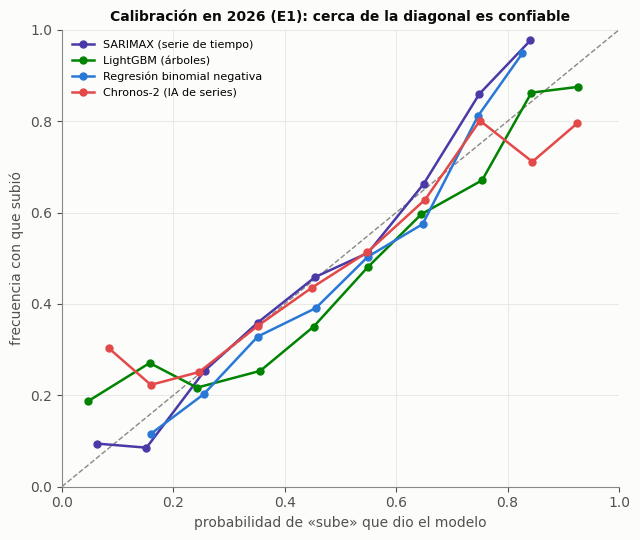

In [11]:
P, U = leer("e1"); P2, T2 = pr.metricas(P, U)
fig, ax = plt.subplots(figsize=(6.5, 5.5)); ax.plot([0, 1], [0, 1], color=MUDO, ls="--", lw=1)
bins = np.linspace(0, 1, 11)
for m in T2.sort_values("BSS sube %", ascending=False).index[:4]:
    d = P2[P2.modelo == m]
    g = d.groupby(pd.cut(d.p_sobre, bins)).agg(p=("p_sobre", "mean"), f=("sobre", "mean"), n=("sobre", "size")).query("n >= 25")
    ax.plot(g.p, g.f, "-o", color=color(m), lw=1.8, ms=5, label=NOMBRE.get(m, m))
ece = {}
for m in T2.sort_values("BSS sube %", ascending=False).index[:4]:
    d = P2[P2.modelo == m]; g = d.groupby(pd.cut(d.p_sobre, bins)).agg(p=("p_sobre", "mean"), f=("sobre", "mean"), n=("sobre", "size")).dropna()
    ece[NOMBRE.get(m, m)] = 100 * (g.n * (g.p - g.f).abs()).sum() / g.n.sum()
print("Distancia media a la diagonal (puntos porcentuales, ponderada por días):", {k: round(v, 1) for k, v in ece.items()})
print("Tasa de días que suben en 2026 (vara de 28 días):", round(100 * P2.drop_duplicates(["fecha", "h"]).sobre.mean(), 1), "%")
ax.set_xlabel("probabilidad de «sube» que dio el modelo"); ax.set_ylabel("frecuencia con que subió")
ax.set_title("Calibración en 2026 (E1): cerca de la diagonal es confiable", fontsize=10); ax.legend(fontsize=8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Lectura.** La tasa de días que suben en 2026 respecto al calendario es 47,6 %. Las curvas de SARIMAX (E1) y Chronos-2 siguen la diagonal: su distancia media a ella es de 3,0 y 3,6 puntos porcentuales, ponderada por días. La regresión se aparta 5,6 puntos y LightGBM, 7,3. Cuando SARIMAX dice «70 % de que suba», sube cerca de esa proporción de las veces. Los extremos reúnen pocos días y son menos seguros.

LightGBM es el que más se aparta: promete más de lo que cumple, que coincide con su cobertura de 71,2 % y justifica combinarlo con SARIMAX en lugar de usarlo solo.

## 5.8 Los picos de 2026 y su aviso la víspera

In [12]:
mejor = T2.sort_values("BSS sube %", ascending=False).index[0]
d = P2[(P2.modelo == mejor) & (P2.h == 1)].copy()
d["día"] = d.fecha.dt.dayofweek.map(dict(enumerate(SEM)))
print(f"Modelo: {NOMBRE.get(mejor, mejor)} (E1: 2020-2025), a 1 día")
top = d.nlargest(12, "d_real")[["fecha", "día", "real", "esperado_cal", "q50", "q10", "q90", "p_sobre", "p_pico", "pico"]]
display(top.rename(columns={"esperado_cal": "anunciaba el calendario", "q50": "predijo", "p_sobre": "P(sube)", "p_pico": "P(pico)"}).round(2))
avisos = pd.DataFrame([{"avisar si P(pico) ≥": f"{u:.0%}", "avisos": int((d.p_pico >= u).sum()),
                        "de esos, eran pico %": 100 * d.pico[d.p_pico >= u].mean() if (d.p_pico >= u).any() else np.nan,
                        "picos avisados %": 100 * d.pico[d.p_pico >= u].sum() / d.pico.sum()} for u in [.2, .3, .4]])
display(avisos.round(1))

Modelo: SARIMAX (serie de tiempo) (E1: 2020-2025), a 1 día


,fecha,día,real,anunciaba el calendario,predijo,q10,q90,P(sube),P(pico),pico
7210,2026-01-03,sáb,178.0,126.14,124.16,107.69,143.15,0.45,0.15,1
8148,2026-05-17,dom,178.0,128.43,132.98,115.36,153.29,0.62,0.26,1
7854,2026-04-05,dom,172.0,130.18,135.00,117.07,155.68,0.62,0.26,1
7511,2026-02-15,dom,140.0,109.22,105.81,91.73,122.05,0.40,0.11,1
7609,2026-03-01,dom,147.0,115.34,122.99,106.62,141.87,0.71,0.36,1
7630,2026-03-04,mié,217.0,170.67,186.86,161.99,215.55,0.79,0.44,1
8981,2026-09-13,dom,164.0,129.13,145.96,126.65,168.23,0.86,0.54,1
8883,2026-08-30,dom,146.0,115.07,130.04,112.80,149.91,0.86,0.54,1
7616,2026-03-02,lun,243.0,194.98,205.80,178.41,237.40,0.68,0.32,1
7308,2026-01-17,sáb,166.0,135.71,131.69,114.18,151.90,0.40,0.11,1


,avisar si P(pico) ≥,avisos,"de esos, eran pico %",picos avisados %
0,20%,113,28.3,69.6
1,30%,60,40.0,52.2
2,40%,25,56.0,30.4


**Lectura.** Con SARIMAX (E1), a un día:

- **Varios picos se vieron venir la víspera:** el 4 de marzo, con P(sube) de 79 %, y el 30 de agosto y el 13 de septiembre, con 86 % cada uno.
- **Otros no:** el 3 de enero (45 %), en plena temporada festiva, y el 21 de agosto (34 %), pocos días después del terremoto.
- **Seis de los doce mayores desvíos son domingos** y dos son sábados. Puede reflejar un cambio en el uso de urgencias que el calendario todavía no recoge, aunque con estos datos no se puede separar de los escalones de la red.
- **El dilema de avisar.** Con P(pico) ≥ 30 % salen 60 avisos, de los que el 40,0 % son pico de verdad, y se cubre el 52,2 % de los picos. Con ≥ 20 % salen 113 avisos, de los que el 28,3 % son pico y se cubre el 69,6 %. El umbral es una decisión del hospital, que pondera el costo de una falsa alarma contra el de un pico no avisado.

---
# 6. Prueba 2: el año a ciegas

El 31 de diciembre de 2025 se hace **una sola predicción** para todo 2026, como la que necesitaría quien
planea el año. El modelo no puede saber el clima ni la IRA de julio: en E2, ese contexto va como «año típico»
(anomalía cero), y las variables de nivel (peso de Nueva EPS, ENSO) se congelan en su valor de
diciembre. Lo programado (calendario, Feria, fiestas) sí entra.

mes                     1     2     3     4     5     6     7     8     9
exp modelo                                                               
e1  anio_pasado      52.2  50.8  23.8  21.2  27.3  22.3  44.1  52.5  34.8
    chronos2_cal      5.9   9.0 -11.4  -7.2  -8.5  -9.5   9.3  18.5  -0.7
    prophet           2.2  -7.7 -29.5 -36.1 -36.4 -39.3 -32.7 -30.9 -46.9
    regresion_anual   1.2   3.0 -22.4 -16.4 -15.7 -19.5  -4.3   5.0 -12.1
    sarimax          -2.4   8.5 -17.0 -14.2 -12.8  -9.8   7.5  15.8  -0.5
e2  anio_pasado      52.2  50.8  23.8  21.2  27.3  22.3  44.1  52.5  34.8
    chronos2_cal     13.0  10.9 -10.4  -6.7  -8.1  -9.6   9.5  18.7  -0.8
    prophet           4.1  -1.4 -25.5 -30.3 -30.1 -32.2 -24.2 -21.6 -39.0
    regresion_anual   4.6   2.7 -22.0 -15.8 -15.2 -19.5  -3.4   5.5 -12.2
    sarimax          20.3  34.0  -0.8   1.5   2.8   3.8  21.9  30.1  10.8

MAPE diario %  error medio del mes %  cob80 %
exp modelo                                                        
e1  anio_pasado               38.6                   36.6     65.4
    chronos2_cal              12.0                    8.9     91.3
    prophet                   29.4                   29.1     17.9
    regresion_anual           14.1                   11.1     54.8
    sarimax                   12.6                    9.8     92.8
e2  anio_pasado               38.6                   36.6     65.4
    chronos2_cal              13.0                    9.8     94.3
    prophet                   24.3                   23.2     23.6
    regresion_anual           14.0                   11.2     53.2
    sarimax                   17.3                   14.0     69.2

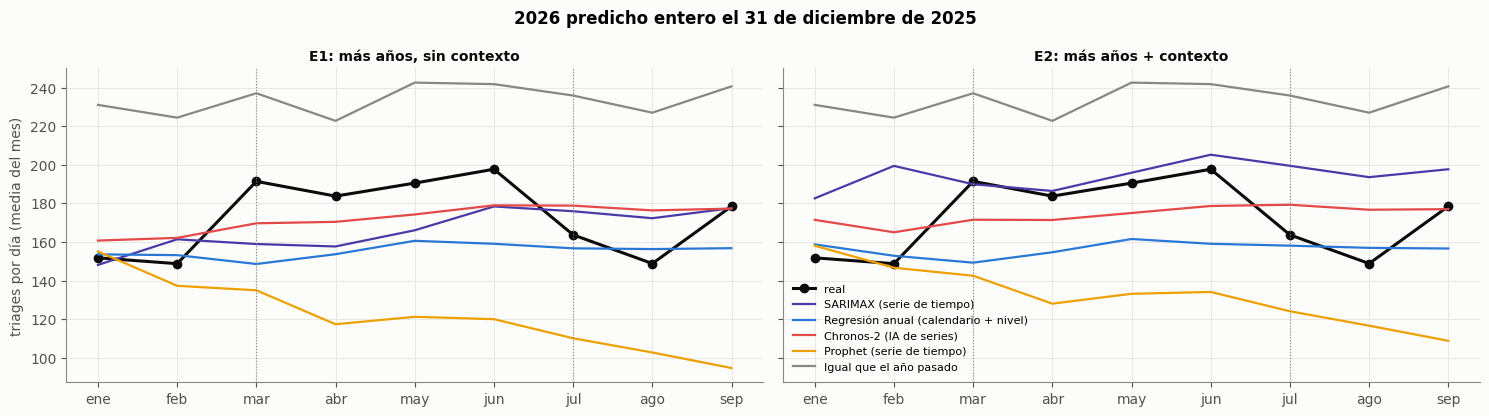

In [13]:
filas = []
for e in ["e1", "e2"]:
    PA, _ = pr.leer(exp=e, anio=True); PA = PA.dropna(subset=["real"])
    PA["mes"] = PA.fecha.dt.month; filas.append(PA.assign(exp=e))
A = pd.concat(filas)
M = A.groupby(["exp", "modelo", "mes"]).agg(pred=("q50", "mean"), lo=("q10", "mean"), hi=("q90", "mean"), real=("real", "mean")).reset_index()
M["error %"] = 100 * (M.pred - M.real) / M.real
display(M.pivot_table(index=["exp", "modelo"], columns="mes", values="error %").round(1))
resA = A.groupby(["exp", "modelo"]).apply(lambda g: pd.Series({
    "MAPE diario %": 100 * ((g.q50 - g.real).abs() / g.real).mean(),
    "error medio del mes %": 100 * (g.groupby("mes").q50.mean() / g.groupby("mes").real.mean() - 1).abs().mean(),
    "cob80 %": 100 * g.real.between(g.q10, g.q90).mean()}))
display(resA.round(1))

meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, e in zip(axes, ["e1", "e2"]):
    r = M[(M.exp == e)].groupby("mes").real.first()
    ax.plot(r.index, r.values, "o-", color=TINTA, lw=2.2, label="real")
    for m in ["sarimax", "regresion_anual", "chronos2_cal", "prophet", "anio_pasado"]:
        g = M[(M.exp == e) & (M.modelo == m)]
        if len(g): ax.plot(g.mes, g.pred, "-", color=color(m), lw=1.6, label=NOMBRE.get(m, m))
    ax.set_xticks(range(1, 10), meses); ax.set_title({"e1": "E1: más años, sin contexto", "e2": "E2: más años + contexto"}[e], fontsize=10)
axes[0].set_ylabel("triages por día (media del mes)"); axes[1].legend(fontsize=8)
for ax in axes:
    for f, t in [(3, "Nueva EPS"), (7, "Nueva EPS")]: ax.axvline(f, color=MUDO, ls=":", lw=.8)
fig.suptitle("2026 predicho entero el 31 de diciembre de 2025", fontweight="bold"); plt.tight_layout(); plt.show()

**Lectura.** La predicción de 2026 entero hecha el 31 de diciembre de 2025, con E1:

- **Chronos-2 es el mejor a meses vista:** se equivoca 8,9 % en la media de cada mes y su rango del 80 % contiene el 91,3 % de los días. Le sigue SARIMAX, con 9,8 % y 92,8 %. La regresión anual queda en 11,1 % (cobertura 54,8 %), Prophet en 29,1 % y «igual que el año pasado» en 36,6 %, porque 2025 estaba en un nivel más alto.
- **El patrón del error es la red.** Chronos-2 y SARIMAX quedan por debajo de lo real de marzo a junio (de −11,4 % a −7,2 % y de −17,0 % a −9,8 %) y por encima en julio y agosto (+9,3 % y +18,5 %; +7,5 % y +15,8 %). Coincide con los escalones de Nueva EPS (cerca de 92 triages por día de marzo a junio y 52 en julio-agosto), que no se podían ver en diciembre.
- **A un año el contexto no ayuda, y a SARIMAX le sienta mal:** con E2 su error mensual pasa de 9,8 % a 14,0 % y su cobertura del 80 % de 92,8 % a 69,2 %; sus errores de enero y febrero son de +20,3 % y +34,0 %. Chronos-2 pasa de 8,9 % a 9,8 % y la regresión anual de 11,1 % a 11,2 %; solo Prophet mejora (de 29,1 % a 23,2 %) sin acercarse a los demás. En esta prueba el clima y la IRA de cada mes van como «año típico» y el peso de Nueva EPS queda congelado en su valor de diciembre, de modo que el contexto no puede aportar información nueva. El resultado de SARIMAX no se atribuye a ninguna variable en particular.

---
# 7. Prueba 3: la hora de saturación

La predicción del día del mejor modelo se reparte en horas con el **perfil horario por día de la
semana de 2025**, que se conoce el 31-12-2025. Se mide si acierta las horas de más carga.

Modelo: SARIMAX (serie de tiempo), a 1 día, 257 días de 2026
Hora pico acertada exacta: 23%; a ±1 hora: 62%
De las 3 horas de más carga, coinciden en promedio: 51%
Error por hora entre 8 y 20 h (MAPE): 33.5 %


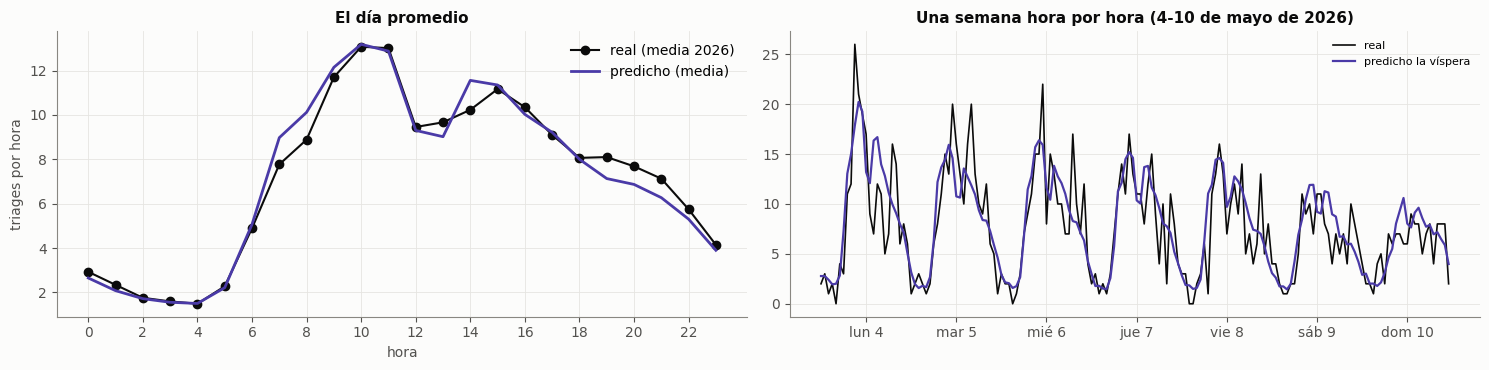

In [14]:
hor = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet"); hor["dia"] = pd.to_datetime(hor.dia)
Hh = hor.pivot_table(index="dia", columns="hora", values="triages", aggfunc="sum").reindex(columns=range(24)).fillna(0)
ref = Hh.loc["2025-01-01":"2025-12-31"]
perfil = (ref.div(ref.sum(axis=1), axis=0)).groupby(ref.index.dayofweek).mean()
d1 = P2[(P2.modelo == mejor) & (P2.h == 1)].set_index("fecha")
real_h = Hh.reindex(d1.index)
pred_h = pd.DataFrame(d1.q50.values[:, None] * perfil.loc[d1.index.dayofweek].values, index=d1.index, columns=range(24))
dia_h = (pred_h - real_h).abs() / real_h.replace(0, np.nan)
pico_real, pico_pred = real_h.idxmax(axis=1), pred_h.idxmax(axis=1)
top3 = np.mean([len(set(real_h.loc[t].nlargest(3).index) & set(pred_h.loc[t].nlargest(3).index)) / 3 for t in d1.index])
print(f"Modelo: {NOMBRE.get(mejor, mejor)}, a 1 día, {len(d1)} días de 2026")
print(f"Hora pico acertada exacta: {(pico_real == pico_pred).mean():.0%}; a ±1 hora: {((pico_real - pico_pred).abs() <= 1).mean():.0%}")
print(f"De las 3 horas de más carga, coinciden en promedio: {top3:.0%}")
print(f"Error por hora entre 8 y 20 h (MAPE): {100 * dia_h.loc[:, 8:20].stack().mean():.1f} %")
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].plot(range(24), real_h.mean().values, "o-", color=TINTA, label="real (media 2026)")
axes[0].plot(range(24), pred_h.mean().values, "-", color=color(mejor), lw=2, label="predicho (media)")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("hora"); axes[0].set_ylabel("triages por hora"); axes[0].legend(); axes[0].set_title("El día promedio")
sem = d1.index[(d1.index >= "2026-05-04") & (d1.index <= "2026-05-10")]
axes[1].plot(np.arange(len(sem) * 24), real_h.loc[sem].values.ravel(), color=TINTA, lw=1.2, label="real")
axes[1].plot(np.arange(len(sem) * 24), pred_h.loc[sem].values.ravel(), color=color(mejor), lw=1.6, label="predicho la víspera")
axes[1].set_xticks(np.arange(len(sem)) * 24 + 12, [f"{SEM[t.dayofweek]} {t.day}" for t in sem]); axes[1].legend(fontsize=8)
axes[1].set_title("Una semana hora por hora (4-10 de mayo de 2026)"); plt.tight_layout(); plt.show()

**Lectura.** Repartiendo el día predicho por SARIMAX con el perfil horario de 2025:

- **La hora pico se acierta con ±1 hora el 62 % de los días**, y exacta el 23 %. De las tres horas de más carga, coinciden en promedio el 51 %.
- **El error por hora es del 33,5 % entre las 8 y las 20 h.** Con 10-17 triages por hora, el azar de Poisson por sí solo ya produce una dispersión de ±25-30 %, por lo que este error no puede bajar mucho con un perfil fijo.
- **El mensaje útil para la operación es por franjas**, no por hora exacta: por ejemplo, «mañana, saturación entre las 9 y las 11 h y entre las 14 y las 15 h». El perfil por día de la semana de 2025 es un supuesto: si el patrón horario cambia, el reparto lo hará mal.

---
# 8. Las razones: qué capa del contexto pesa

Se ajustan dos modelos en el último origen (2026-09-13) con todo el contexto:
- **LightGBM** (mediana a 1 día): cuánto de su capacidad de separar días usa cada capa (ganancia);
- **la regresión**: cuánto mueve cada capa la predicción cuando sus variables se corren una desviación
  típica.

C:\Users\ad6708\Documents\puebas\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


,LightGBM: % de la ganancia,"Regresión: efecto de 1 desviación, % (suma de |efectos|)"
nivel,28.1,30.6
calendario,22.1,114.2
memoria,17.8,7.6
clima,9.0,3.2
salud,8.3,3.6
estacion,5.2,2.1
social,5.0,1.1
red,3.2,0.3
enso,0.8,0.9
eventos,0.5,10.4


Las 12 variables externas más usadas por LightGBM (% de la ganancia):
ext_red_nueva_peso                 1.70
ext_soc_lesiones_personales        1.59
ext_red_nueva_cambio               1.51
ext_sal_ira_total                  1.40
ext_sal_ev356                      1.28
ext_soc_homicidio                  1.21
ext_soc_violencia_intrafamiliar    1.14
ext_sal_ira_0_4                    1.11
ext_sal_consultas_todas            1.08
ext_soc_lesiones_transito          1.03
ext_cli_radiacion_cambio           0.97
ext_sal_ev300                      0.91



Las 49 variables externas suman 26.9 % de la ganancia; la mayor aporta 1.70 % y la mediana 0.63 %.


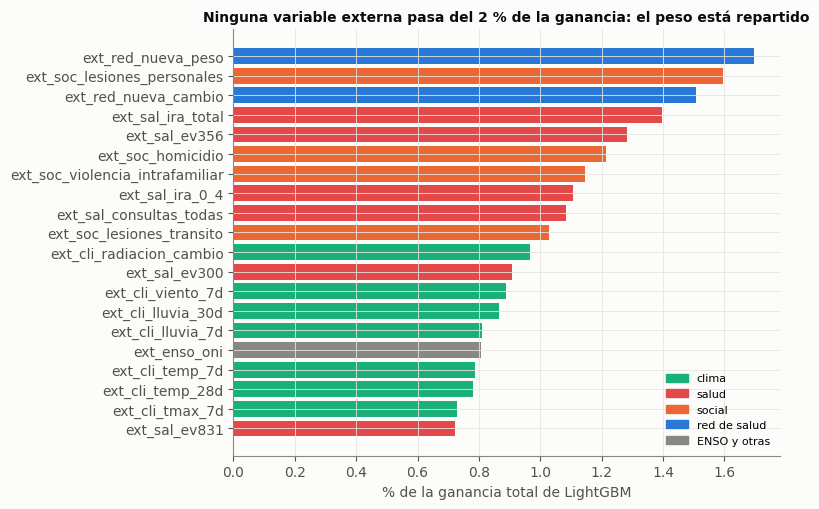

In [15]:
import lightgbm as lgb
pr.usar("e2")
o = pd.Timestamp(pr.ULTIMO_ORIGEN)
ctx = tuple(c.reindex(y.index) for c in pr.contexto(cal.index))
X = pr.rasgos(y, cal.reindex(y.index), 1, ctx).loc[:o]; yy = y.loc[:o]
ok = X.notna().all(axis=1) & yy.notna(); X, yy = X[ok], yy[ok]; X = X.loc[:, X.std() > 0]
m = lgb.LGBMRegressor(objective="quantile", alpha=.5, **pr.LightGBM.PARAM).fit(X, np.log(yy))
gan = pd.Series(m.booster_.feature_importance("gain"), index=X.columns)
capa = pd.Series(pr.capas(X.columns))
r = sm.NegativeBinomial(yy.values, sm.add_constant(X.values, has_constant="add")).fit(disp=0, maxiter=300)
b = pd.Series(r.params[1:-1], index=X.columns)
efecto = (b * X.std()).abs().groupby(capa).sum()
pesos = pd.DataFrame({"LightGBM: % de la ganancia": 100 * gan.groupby(capa).sum() / gan.sum(),
                      "Regresión: efecto de 1 desviación, % (suma de |efectos|)": 100 * (np.exp(efecto) - 1)}).sort_values("LightGBM: % de la ganancia", ascending=False)
display(pesos.round(1))
print("Las 12 variables externas más usadas por LightGBM (% de la ganancia):")
ext = gan[[c for c in gan.index if c.startswith(("ext_", "fut_"))]]
pe = (100 * ext / gan.sum()).sort_values(ascending=False)
print(pe.head(12).round(2).to_string())
print(f"\nLas {len(pe)} variables externas suman {pe.sum():.1f} % de la ganancia; la mayor aporta {pe.max():.2f} % y la mediana {pe.median():.2f} %.")
fig, ax = plt.subplots(figsize=(8, 5.2)); t = pe.head(20)[::-1]
cap = pr.capas(list(t.index))
ax.barh(t.index, t.values, color=[{"clima": AQUA, "salud": ROJO, "social": NARANJA, "red": AZUL}.get(cap[n], MUDO) for n in t.index])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c_, label=n_) for n_, c_ in [("clima", AQUA), ("salud", ROJO), ("social", NARANJA), ("red de salud", AZUL), ("ENSO y otras", MUDO)]], fontsize=8, loc="lower right")
ax.set_xlabel("% de la ganancia total de LightGBM"); ax.set_title("Ninguna variable externa pasa del 2 % de la ganancia: el peso está repartido", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.** Según LightGBM con todo el contexto, ajustado en el último origen:

- **Lo interno manda.** El nivel de los últimos 28 días pesa 28,1 % de la ganancia, el calendario 22,1 % y la memoria 17,8 %. La estación suma 5,2 %.
- **Lo externo suma 26,9 %**, repartido entre clima (9,0 %), salud (8,3 %), social (5,0 %), red de salud (3,2 %), ENSO (0,8 %), eventos (0,5 %) y catástrofes (0,0 %). Las variables más usadas son el peso y el cambio de Nueva EPS, las lesiones personales y la IRA total (1,4-1,7 % cada una).
- **La regresión coincide.** La suma de los efectos de una desviación típica en las variables de calendario equivale a 114,2 % y en el nivel a 30,6 %, mientras que cada capa externa queda entre 0,1 % y 3,6 %. Los eventos, con 10,4 %, son la excepción, porque son marcas de días concretos. La regresión con las 77 columnas no pudo invertir su matriz de segundas derivadas (la advertencia de la celda), un signo de columnas muy correlacionadas.

El contexto entra en las decisiones del modelo, pero cada variable aporta poco, y en 2026 eso no se tradujo en mejores predicciones del total. El peso bajo de la red de salud no indica que Nueva EPS no importe: el nivel de 28 días ya recoge buena parte de los escalones. La lectura que queda en pie, en línea con los cuadernos 07, 13 y 14, es que el total lo mueven el calendario y la red, y el efecto del entorno vive en subseries como la respiratoria del hospital y se achica en el total por su peso; el clima de la ciudad no llega al total como una versión reducida de la IRA (cuaderno 17). Este reparto describe cómo usa el modelo la información; no es un efecto causal.

---
# 9. MedGemma, un modelo de lenguaje médico, como pronosticador

Se probó `medgemma:latest` (4,3 B) en un servidor, con 19 consultas de 7 días cada una. Cada consulta recibe **la misma información que E2**, en texto: 8 semanas de
triage, el calendario y los eventos que vienen, y el contexto de la ciudad (IRA, clima, Nueva EPS,
lesiones). Dan un número por día, no una distribución, así que se comparan solo en el error del número
y en si aciertan la dirección (sube o baja), **en los mismos orígenes** que los demás.

In [16]:
PL, UL = pr.leer(exp="e2")
llm = PL[PL.modelo.str.startswith("llm")]
if len(llm):
    ors_llm = llm.origen.unique()
    comp = []
    for e in ["e0", "e1", "e2", "e3"]:
        P, _ = leer(e); comp.append(P[P.origen.isin(ors_llm)].assign(modelo=lambda d, e=e: d.modelo + " · " + e))
    comp.append(llm)
    CP, TL = pr.metricas(pd.concat(comp), UL)
    TL["dirección (sube/baja) %"] = CP.assign(ok=lambda d: (np.sign(d.d_pred) == np.sign(d.d_real))).groupby("modelo").ok.mean() * 100
    display(TL[["dirección (sube/baja) %", "error <=10 %", "MAPE %", "n"]].sort_values("MAPE %").round(1))
    print("Respuestas de MedGemma del servidor (los 7 números de cada consulta):")
    print(llm[llm.modelo.str.contains("servidor")].groupby("origen").q50.apply(lambda s: list(s.astype(int))).head(8).to_string())

,dirección (sube/baja) %,error <=10 %,MAPE %,n
modelo,,,,
sarimax · e0,69.9,63.2,8.8,133.0
sarimax · e1,65.4,66.9,8.8,133.0
sarimax · e3,61.7,61.7,8.9,133.0
lightgbm · e1,71.4,62.4,9.0,133.0
chronos2_cal · e3,72.9,63.2,9.0,133.0
glm_binneg · e1,66.2,62.4,9.0,133.0
glm_binneg · e3,63.2,63.9,9.1,133.0
chronos2_cal · e0,66.2,65.4,9.1,133.0
chronos2_cal · e1,67.7,63.2,9.1,133.0


Respuestas de MedGemma del servidor (los 7 números de cada consulta):


origen
2025-12-31      [145, 130, 120, 110, 100, 90, 80]
2026-01-14    [145, 138, 149, 134, 163, 193, 184]
2026-01-28    [158, 149, 165, 135, 170, 140, 152]
2026-02-11    [235, 240, 220, 210, 250, 230, 225]
2026-02-25    [158, 159, 160, 161, 162, 163, 164]
2026-03-11    [245, 220, 200, 190, 230, 210, 200]
2026-03-25    [235, 228, 210, 160, 190, 200, 215]
2026-04-08    [238, 215, 195, 200, 220, 210, 205]


**Lectura.** MedGemma (servidor, 4,3 B) es el peor en error numérico: MAPE de 19,7 %, frente al 12,6 % del ingenuo, y solo un tercio de los días (33,8 %) con error de 10 % o menos. En la dirección de sube/baja queda en 62,4 %, cercano a los demás, y esa medida es más gruesa que el número.

Sus respuestas tienen escaleras que bajan de 10 en 10 (145, 130, 120, 110, 100, 90, 80), números consecutivos (158, 159, 160, 161, 162, 163, 164) y semanas sin la forma lunes-domingo. Un modelo de lenguaje rellena números con forma de serie y no los pronostica; para series, la IA que funciona es Chronos-2. La prueba usa 19 consultas, y por eso solo permite descartar a MedGemma como pronosticador del número, no como asistente en otras tareas.

---
# 10. Qué se conserva y qué se descarta

La decisión se toma con el criterio de la sección 4: acierto en sube/baja, mejora de la probabilidad y cobertura del 80 %.

| Modelo o técnica | Decisión | Por qué |
|---|---|---|
| **SARIMAX + LightGBM (combinación)** | **líder** | Cumple los tres criterios a la vez: 69,4 % de acierto, +21,1 % de BSS y cobertura de 80,3 %. Es la única que supera a SARIMAX con significancia (en los meses estables) |
| **SARIMAX** (serie de tiempo que se corrige cada día) | se conserva, como componente | Mejor modelo individual: sigue los escalones de la red y da rangos honestos; empata en dirección |
| **LightGBM** (árboles con refuerzo, sin afinar) | se conserva, como componente | Es la señal que queda en los meses estables, pero con cobertura de 71,2 % se confía de más si va solo |
| Jerárquico (Nueva EPS + resto) | se conserva **para explicar** | Empata en precisión y separa cuánto de la predicción es Nueva EPS |
| Chronos-2 | se conserva **para el año a ciegas** | Es el mejor a meses vista (8,9 % de error mensual) |
| Regresión binomial negativa | complemento | Da razones legibles; empata o pierde en dirección |
| XGBoost y GradientBoosting afinados | se descartan | No mejoran a LightGBM |
| Contexto externo completo sobre el total | **no entra al modelo del total a 1-7 días** | Empeora o no mejora en todas las familias evaluadas (E2 y E3) |
| Prophet, MedGemma | se descartan | Peores que el control o que el ingenuo |

**Por técnica:** combinar una serie de tiempo con árboles de refuerzo es lo mejor. Les siguen cada uno por separado (empatados entre sí), después la IA preentrenada y la regresión, y al final las series sin memoria y los modelos de lenguaje.

---
# 11. Conclusiones y límites

## Conclusiones

**El mejor modelo es la combinación SARIMAX + LightGBM**, que promedia una serie de tiempo que se corrige cada día con un ensamble de árboles de decisión. Usa los registros de triage de 2020-2025 y el calendario de Colombia. En 2026, un año que no vio, cumple el criterio completo:

- acierta si el día sube o baja frente al calendario el **69,4 %** con la vara de 28 días y el **64,1 %** con la vara rápida, que es la cifra de anticipar el día;
- su mejora de la probabilidad de «sube» es de **+21,1 %** y la de pico de +16,5 %;
- su rango del 80 % cubre el **80,3 %** de los días;
- el MAPE es 8,9 %, a título informativo.

**Lo que se aprendió:**

1. **La historia larga es lo que más mejora** a los modelos con memoria (E0 a E1).
2. **El contexto completo, siempre encendido (E2), empeoró la probabilidad** de la regresión y de LightGBM, con intervalos que descartan el azar en el Brier de ambos. La explicación respaldada por los datos es sobreajuste: 49 variables externas (28 de ellas con valor casi todos los días) frente a 2.162 días de entrenamiento, con un peso repartido sin que ninguna domine. Esto no equivale a que lo externo no sirva: el diseño no podía ver efectos episódicos y condicionados que se diluyen en el total.
3. **El nivel del total lo mueve Nueva EPS, a escalones imprevisibles.** Buena parte del acierto de 65-70 % con la vara de 28 días consistía en seguir esos escalones; con la vara rápida baja a 58-64 %.
4. **En los meses estables solo los árboles anticipan algo** (63,3 % con LightGBM).
5. **Ningún modelo individual es claramente superior en dirección**: están empatados con SARIMAX. Combinarlos sí mejora en los meses estables.
6. **A meses vista el mejor es Chronos-2** (8,9 % de error mensual), y la hora pico se acierta con ±1 hora el 62 % de los días.

## Límites del análisis

- SARIMAX con contexto completo (E2) no se evaluó en la prueba de corto plazo, y Chronos-2 con contexto se corrió con un origen cada 7 días (37 orígenes), de modo que la comparación entre E1 y E2 en esos dos modelos tiene menos respaldo que en la regresión y los árboles.
- Todo se midió en 2026, un único año con un régimen de red muy particular (escalones de Nueva EPS y un terremoto). Con 257 orígenes, las diferencias de 1-3 puntos de acierto no se distinguen del azar.
- No existe un archivo histórico de pronósticos del clima ni de la IRA. Los resultados valen para un modelo que usa lo observado hasta el día anterior; no miden el efecto de un buen pronóstico.
- Las pruebas son sobre el triage total. El efecto del entorno en la fracción respiratoria o por banda de edad se estudia en los cuadernos posteriores y no puede juzgarse con estos resultados.
- El calendario institucional de Nueva EPS no está incluido: es una fuente de error visible tanto en las pruebas de corto plazo como en la del año a ciegas.